# Lab 2 — What Did the Campaign Deliver?
Name: Zhmurko Vira,  | Group: KM-41

## Setup

In [1]:
import importlib.util
import os
import subprocess
import sys
import time
import warnings

started = time.perf_counter()
required = {"kagglehub": "kagglehub>=0.3,<2", "pandas": "pandas>=2.2,<3",
            "numpy": "numpy>=1.26,<3", "matplotlib": "matplotlib>=3.8,<4",
            "pyarrow": "pyarrow>=15"}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
warnings.filterwarnings("ignore", message="IProgress not found.*")

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = os.environ.get("LAB2_DATA_DIR")
if DATA is None:
    DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda x: f"{x:.1f}")

for frame in (programs, viewings, commercials):
    frame["start_ts"] = pd.to_datetime(frame.start_ts)
    if "end_ts" in frame:
        frame["end_ts"] = pd.to_datetime(frame.end_ts)
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights.broadcast_date)
programs["broadcast_date"] = pd.to_datetime(programs.broadcast_date)
assert commercials.ad_airing_id.is_unique and programs.telecast_id.is_unique
assert not daily_weights.duplicated(["respondent_id", "broadcast_date"]).any()

decoded = viewer_attributes.merge(attributes, on="attr_id", validate="many_to_one")
assert len(decoded) == len(viewer_attributes)
person_days = daily_weights.loc[daily_weights.resp_type.isin(["R", "L"])].copy()
person_ids = pd.Index(person_days.respondent_id.unique(), name="respondent_id")
demo = pd.DataFrame(index=person_ids)
demo["age"] = decoded.loc[decoded.attr_id.eq(300)].set_index("respondent_id").value
demo["sex"] = decoded.loc[decoded.attr_group.eq("Sex")].set_index("respondent_id").attr_name
assert demo.notna().all().all()
monthly_weights = person_days.groupby("respondent_id").weight.mean()
person_universe = person_days.groupby("broadcast_date").weight.sum()
target_ids = demo.index[demo.age.between(18, 49)]
target_days = person_days.loc[person_days.respondent_id.isin(target_ids)]
target_universe = target_days.groupby("broadcast_date").weight.sum()
daily_n = person_days.groupby("broadcast_date").respondent_id.nunique()
daily_weight_lookup = person_days.set_index(["respondent_id", "broadcast_date"]).weight
BIG = {"CBS", "NBC", "ABC", "FOX", "FNC"}
SMALL = {"FX", "BRAVO", "HGTV", "FOOD", "HIST"}

100%|██████████| 8.00M/8.00M [00:01<00:00, 5.34MB/s]

Extracting files...


## Task 1.1 — Size

In [2]:
campaign_log = commercials.loc[commercials.brand.eq("BRAND_A")].copy()
assert len(campaign_log) == 300
assert campaign_log.length_sec.eq(30).all()
print("Spots:", len(commercials))
print("Pods:", commercials.pod_id.nunique())
print("Brands:", commercials.brand.nunique())
print("Categories:", commercials.category.nunique())
print("BRAND_A spots:", len(campaign_log))
display(campaign_log.groupby("network_code").size().rename("BRAND_A spots").to_frame())

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,BRAND_A spots
network_code,
ABC,29
BRAVO,33
CBS,22
FNC,40
FOOD,33
FOX,13
FX,38
HGTV,39
HIST,37


## Task 1.2 — Ad load

In [3]:
cursor = commercials[["network_code", "start_ts", "length_sec"]].copy()
cursor["end_ts"] = cursor.start_ts + pd.to_timedelta(cursor.length_sec, unit="s")
hour_pieces = []
while not cursor.empty:
    hour = cursor.start_ts.dt.floor("h")
    stops = pd.concat([cursor.end_ts, hour + pd.Timedelta(hours=1)], axis=1).min(axis=1)
    hour_pieces.append(pd.DataFrame({"network_code": cursor.network_code,
        "hour": hour, "ad_seconds": (stops-cursor.start_ts).dt.total_seconds()}))
    cursor["start_ts"] = stops
    cursor = cursor.loc[cursor.start_ts.lt(cursor.end_ts)].copy()
hour_load = pd.concat(hour_pieces).groupby(["network_code", "hour"]).ad_seconds.sum()/60
assert np.isclose(hour_load.sum()*60, commercials.length_sec.sum())
ad_load = hour_load.groupby("network_code").agg(["mean", "size"])
ad_load.columns = ["Ad minutes per active hour", "Hours carrying ads"]
ad_load = ad_load.sort_values("Ad minutes per active hour", ascending=False)
display(ad_load)
print("Heaviest ad load:", ad_load.index[0])

,Ad minutes per active hour,Hours carrying ads
network_code,,
FNC,15.6,743
BRAVO,13.4,623
HGTV,13.3,621
HIST,13.2,622
FOOD,13.1,621
FX,12.9,621
CBS,12.1,429
FOX,11.8,196
NBC,11.8,300


Heaviest ad load: FNC


**Answer:**

Broadcast networks leave some hours to local stations, so the ads sold in those hours are not in this national log. Paid programming and the vice-presidential debate also have no national commercials here.

## Task 1.3 — Price everything

In [4]:
ads = commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id",
                        how="left", validate="many_to_one")
assert ads.program_name.notna().all()
ads["broadcast_date"] = (ads.start_ts - pd.Timedelta(hours=6)).dt.normalize()
shifted = ads.start_ts - pd.Timedelta(hours=6)
ads["weekday"] = shifted.dt.dayofweek
ads["minute"] = shifted.dt.hour*60 + shifted.dt.minute + shifted.dt.second/60
program_rates = rate_card.loc[rate_card.program_name.notna() & rate_card.program_name.ne("")]
assert not program_rates.duplicated(["network_code", "program_name"]).any()
ads = ads.merge(program_rates[["network_code", "program_name", "daypart", "cost_30s_usd"]],
    on=["network_code", "program_name"], how="left", validate="many_to_one")
ads = ads.rename(columns={"daypart": "selling_daypart"})
ads["program_rate"] = ads.cost_30s_usd.notna()

def broadcast_minute(clock):
    hours, minutes = map(int, clock.split(":"))
    return hours*60 + minutes - 360

time_rates = rate_card.loc[rate_card.program_name.isna() | rate_card.program_name.eq("")].copy()
time_rates["start_min"] = time_rates.start_time.map(broadcast_minute)
time_rates["end_min"] = time_rates.end_time.map(broadcast_minute)
time_matches = np.zeros(len(ads), dtype=int)
for row in time_rates.itertuples():
    selected = (ads.network_code.eq(row.network_code) & ads.weekday.isin(row.weekdays)
                & ads.minute.ge(row.start_min) & ads.minute.lt(row.end_min))
    time_matches += selected.to_numpy()
    # тариф програми вже є — його не чіпаю
    fill = selected & ~ads.program_rate
    ads.loc[fill, "selling_daypart"] = row.daypart
    ads.loc[fill, "cost_30s_usd"] = row.cost_30s_usd
assert (time_matches == 1).all()
ads["cost_usd"] = ads.cost_30s_usd * ads.length_sec/30
print("Spots without a price:", int(ads.cost_usd.isna().sum()))
assert ads.cost_usd.notna().all() and ads.cost_usd.gt(0).all()
ads["program_cost"] = ads.cost_usd.where(ads.program_rate, 0)
rate_values = ads.groupby("network_code").agg(total=("cost_usd", "sum"),
    program=("program_cost", "sum"))
rate_values["Rate-card value (USD M)"] = rate_values.total/1e6
rate_values["Share from program rows"] = rate_values.program/rate_values.total
display(rate_values[["Rate-card value (USD M)", "Share from program rows"]].assign(
    **{"Share from program rows": rate_values["Share from program rows"].map("{:.3f}".format)}))
campaign = ads.loc[ads.brand.eq("BRAND_A")].copy().set_index("ad_airing_id", drop=False)

Spots without a price: 0


,Rate-card value (USD M),Share from program rows
network_code,,
ABC,708.8,0.432
BRAVO,25.3,0.000
CBS,818.8,0.230
FNC,315.8,0.000
FOOD,42.1,0.000
FOX,696.2,0.835
FX,42.5,0.000
HGTV,58.1,0.000
HIST,40.1,0.000


## Task 2.1 — Delivery

In [5]:
sessions_by_network = {network: frame for network, frame in
    viewings.loc[viewings.resp_type.isin(["R", "L"])].groupby("network_code")}

def spot_exposures(spots):
    parts = []
    for spot in spots.itertuples(index=False):
        sessions = sessions_by_network[spot.network_code]
        seen = sessions.loc[sessions.start_ts.le(spot.start_ts)
                            & sessions.end_ts.gt(spot.start_ts), "respondent_id"].unique()
        parts.append(pd.DataFrame({"ad_airing_id": spot.ad_airing_id,
            "respondent_id": seen, "network_code": spot.network_code,
            "broadcast_date": spot.broadcast_date}))
    result = pd.concat(parts, ignore_index=True)
    keys = pd.MultiIndex.from_frame(result[["respondent_id", "broadcast_date"]])
    result["weight"] = daily_weight_lookup.reindex(keys).to_numpy()
    assert result.weight.notna().all()
    return result.join(demo, on="respondent_id", validate="many_to_one")

exposures = spot_exposures(campaign)
assert not exposures.duplicated(["ad_airing_id", "respondent_id"]).any()
target_exposures = exposures.loc[exposures.age.between(18, 49)]
spot_metrics = campaign[["network_code", "broadcast_date", "selling_daypart", "cost_usd"]].copy()
spot_metrics["P2+ impressions"] = exposures.groupby("ad_airing_id").weight.sum().reindex(campaign.index, fill_value=0)
spot_metrics["A18-49 impressions"] = target_exposures.groupby("ad_airing_id").weight.sum().reindex(campaign.index, fill_value=0)
spot_metrics["P2+ rating"] = spot_metrics["P2+ impressions"] / spot_metrics.broadcast_date.map(person_universe)*100
spot_metrics["A18-49 rating"] = spot_metrics["A18-49 impressions"] / spot_metrics.broadcast_date.map(target_universe)*100

def delivery(frame, ids, prefix):
    impressions = spot_metrics[f"{prefix} impressions"].sum()
    grps = spot_metrics[f"{prefix} rating"].sum()
    reached = pd.Index(frame.respondent_id.unique())
    reach = monthly_weights.reindex(reached).sum()/monthly_weights.reindex(ids).sum()*100
    return {"impressions": impressions, "grps": grps, "reach": reach,
            "frequency": grps/reach}

p2 = delivery(exposures, person_ids, "P2+")
a18 = delivery(target_exposures, target_ids, "A18-49")
for label, result in [("P2+", p2), ("A18-49", a18)]:
    print(f"{label} impressions (M):", f"{result['impressions']/1e6:.1f}")
    print(f"{label} GRPs:", f"{result['grps']:.1f}")
    print(f"{label} reach (%):", f"{result['reach']:.1f}")
    print(f"{label} average frequency:", f"{result['frequency']:.2f}")

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.03
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 1.98


## Task 2.2 — Frequency distribution

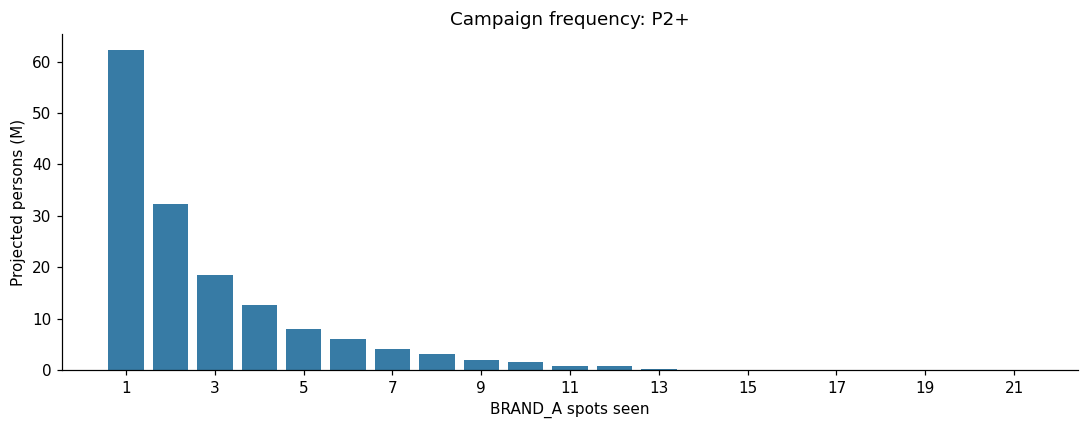

Share of impressions at 5+ exposures: 0.444
Median spots seen (weighted): 2


In [6]:
frequency = exposures.groupby("respondent_id").ad_airing_id.nunique().to_frame("spots")
frequency["monthly_weight"] = monthly_weights.reindex(frequency.index)
distribution = frequency.groupby("spots").monthly_weight.sum().reindex(
    range(1, int(frequency.spots.max())+1), fill_value=0)/1e6
assert np.isclose(distribution.sum()*1e6, frequency.monthly_weight.sum())
loyal_ids = frequency.index[frequency.spots.ge(5)]
five_plus_share = exposures.loc[exposures.respondent_id.isin(loyal_ids), "weight"].sum()/exposures.weight.sum()
fig, ax = plt.subplots()
ax.bar(distribution.index, distribution, color="#377ba5")
ax.set(xlabel="BRAND_A spots seen", ylabel="Projected persons (M)",
       title="Campaign frequency: P2+", xticks=range(1, int(distribution.index.max())+1, 2))
fig.tight_layout()
plt.show()
print("Share of impressions at 5+ exposures:", f"{five_plus_share:.3f}")
ordered = frequency.sort_values("spots")
median_frequency = int(ordered.spots.iloc[np.searchsorted(ordered.monthly_weight.cumsum(),
    ordered.monthly_weight.sum()/2)])
print("Median spots seen (weighted):", median_frequency)

**Answr:** The average frequency is 3.03, but the median person reached saw only 2 spots, so one average hides a lot of the spread. People with 5 or more exposures account for 44.4% of impressions; I would show the histogram with the average rather than use the average on its own.

## Task 2.3 — On target?

In [7]:
target_share = a18["impressions"]/p2["impressions"]
universe_target_share = target_universe.sum()/person_universe.sum()
target_mix = spot_metrics.groupby("network_code")[["P2+ impressions", "A18-49 impressions"]].sum()
target_mix["Share on A18-49"] = target_mix["A18-49 impressions"]/target_mix["P2+ impressions"]
print("Share of impressions on A18-49:", f"{target_share:.3f}")
print("A18-49 share of the daily universe:", f"{universe_target_share:.3f}")
display(pd.DataFrame({"P2+ impressions (M)": target_mix["P2+ impressions"]/1e6,
    "A18-49 impressions (M)": target_mix["A18-49 impressions"]/1e6,
    "Share on A18-49": target_mix["Share on A18-49"].map("{:.3f}".format)}))

Share of impressions on A18-49: 0.194
A18-49 share of the daily universe: 0.423


,P2+ impressions (M),A18-49 impressions (M),Share on A18-49
network_code,,,
ABC,94.2,17.0,0.180
BRAVO,5.1,2.8,0.554
CBS,89.0,13.7,0.154
FNC,57.8,2.7,0.047
FOOD,9.5,3.0,0.316
FOX,76.3,18.4,0.242
FX,8.5,5.6,0.651
HGTV,24.7,7.6,0.306
HIST,12.3,2.5,0.202


**Answer:** Only 19.4% of impressions went to A18–49, compared with 42.3% of the daily person universe, so the campaign under-delivered on its target mix. FNC is especially weak at 4.7%, and the large CBS, ABC and NBC audiences are also mostly outside the target; FX (65.1%) and Bravo (55.4%) fit better but account for far fewer impressions.

## Task 3.1 — Cost

In [8]:
campaign_cost = campaign.cost_usd.sum()
p2_cpm, a18_cpm = campaign_cost/p2["impressions"]*1000, campaign_cost/a18["impressions"]*1000
p2_cpp, a18_cpp = campaign_cost/p2["grps"], campaign_cost/a18["grps"]
print("Campaign cost (USD):", f"{campaign_cost:.0f}")
print("P2+ CPM (USD):", f"{p2_cpm:.2f}")
print("P2+ CPP (USD):", f"{p2_cpp:.0f}")
print("A18-49 CPM (USD):", f"{a18_cpm:.2f}")
print("A18-49 CPP (USD):", f"{a18_cpp:.0f}")

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [9]:
by_network = spot_metrics.groupby("network_code").agg(spots=("cost_usd", "size"),
    cost=("cost_usd", "sum"), p_impressions=("P2+ impressions", "sum"),
    target_impressions=("A18-49 impressions", "sum"))
by_network["P2+ CPM"] = by_network.cost/by_network.p_impressions*1000
by_network["A18-49 CPM"] = by_network.cost/by_network.target_impressions*1000
network_table = pd.DataFrame({"Spots": by_network.spots, "Cost (USD)": by_network.cost.map("{:.0f}".format),
    "P2+ impressions (M)": by_network.p_impressions/1e6,
    "A18-49 impressions (M)": by_network.target_impressions/1e6,
    "P2+ CPM (USD)": by_network["P2+ CPM"].map("{:.2f}".format),
    "A18-49 CPM (USD)": by_network["A18-49 CPM"].map("{:.2f}".format)})
display(network_table.sort_values("Spots", ascending=False))

,Spots,Cost (USD),P2+ impressions (M),A18-49 impressions (M),P2+ CPM (USD),A18-49 CPM (USD)
network_code,,,,,,
FNC,40,526300,57.8,2.7,9.11,193.70
HGTV,39,230000,24.7,7.6,9.33,30.45
FX,38,92200,8.5,5.6,10.82,16.61
HIST,37,79640,12.3,2.5,6.46,32.05
FOOD,33,96620,9.5,3.0,10.19,32.29
BRAVO,33,49610,5.1,2.8,9.76,17.61
ABC,29,1625700,94.2,17.0,17.26,95.69
CBS,22,1488700,89.0,13.7,16.73,108.72
NBC,16,796800,41.4,7.8,19.23,101.72


**Answer:** FOX took the most money (2,434,700), followed by ABC (1,625,700) and CBS (1,488,700). FX and Bravo  were the cheapest networks for A18–49 at 16.61 and 17.61 CPM, while FNC cost $193.70  despite its low P2+ CPM.

## Task 3.3 — Guarantee

In [10]:
guarantee_met = bool(p2["grps"] >= 150)
makegood_grps = max(0, 150-p2["grps"])
makegood_value = makegood_grps*p2_cpp
print("Guarantee met:", guarantee_met)
print("Make-good GRPs owed:", f"{makegood_grps:.1f}")
print("Value of make-goods (USD):", f"{makegood_value:.0f}")

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [11]:
big_ids = pd.Index(exposures.loc[exposures.network_code.isin(BIG), "respondent_id"].unique())
small_ids = pd.Index(exposures.loc[exposures.network_code.isin(SMALL), "respondent_id"].unique())
period_universe = monthly_weights.sum()
big_reach = monthly_weights.reindex(big_ids).sum()/period_universe*100
small_reach = monthly_weights.reindex(small_ids).sum()/period_universe*100
overlap = monthly_weights.reindex(big_ids.intersection(small_ids)).sum()/period_universe*100
independent_overlap = big_reach*small_reach/100
added_reach = p2["reach"]-big_reach
assert np.isclose(p2["reach"], big_reach+small_reach-overlap)
big_cost = campaign.loc[campaign.network_code.isin(BIG), "cost_usd"].sum()
small_cost = campaign.loc[campaign.network_code.isin(SMALL), "cost_usd"].sum()
small_added_cpp = small_cost/added_reach
big_reach_cpp = big_cost/big_reach
print("Reach, big networks (%):", f"{big_reach:.1f}")
print("Reach, small networks (%):", f"{small_reach:.1f}")
print("Reach, whole campaign (%):", f"{p2['reach']:.1f}")
print("Overlap (%):", f"{overlap:.1f}")
print("Overlap if independent (%):", f"{independent_overlap:.1f}")
print("Reach added by small networks (points):", f"{added_reach:.1f}")
print("Cost per added reach point, small (USD):", f"{small_added_cpp:.0f}")
print("Cost per reach point, big (USD):", f"{big_reach_cpp:.0f}")
print("Big-network reach among small-network viewers (%):", f"{overlap/small_reach*100:.1f}")

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456
Big-network reach among small-network viewers (%): 70.2


**Answer:** Some people saw spots on both groups, so adding the two reach figures counts them twice: the overlap is 8.7% rather than 4.9% under independence. Among people reached on the small networks, 70.2% were also reached on the big ones, versus 39.8% overall, which could reflect heavier viewing across several networks. Small networks added 3.7 reach points at 148,706 each, below the big-network cost of 172,456 per point, so their incremental P2+ reach looks reasonably priced here.

## Task 5 — How sure are we?

In [12]:
spot_metrics["panelists"] = exposures.groupby("ad_airing_id").respondent_id.nunique().reindex(campaign.index, fill_value=0)
spot_metrics["n"] = spot_metrics.broadcast_date.map(daily_n)
p = spot_metrics["P2+ rating"]/100
spot_metrics["SE"] = np.sqrt(p*(1-p)/spot_metrics.n)*100
# нульовий рейтинг не має визначеної відносної похибки
spot_metrics["relative_SE"] = spot_metrics.SE/spot_metrics["P2+ rating"].replace(0, np.nan)
uncertainty = spot_metrics.groupby("network_code").agg(
    median_panelists=("panelists", "median"), median_relative_SE=("relative_SE", "median"),
    zero_spots=("panelists", lambda x: int(x.eq(0).sum())))
display(uncertainty.assign(median_relative_SE=uncertainty.median_relative_SE.map("{:.3f}".format)))
zero_spots = int(spot_metrics.panelists.eq(0).sum())
relative_big = spot_metrics.loc[spot_metrics.network_code.isin(BIG), "relative_SE"].median()
relative_small = spot_metrics.loc[spot_metrics.network_code.isin(SMALL), "relative_SE"].median()
women_young = exposures.loc[exposures.sex.eq("Female") & exposures.age.between(18, 34)]
women_counts = women_young.groupby("ad_airing_id").respondent_id.nunique().reindex(campaign.index, fill_value=0)
women_zero = int(women_counts.eq(0).sum())
assert spot_metrics.loc[spot_metrics.panelists.eq(0), "P2+ rating"].eq(0).all()
print("Spots seen by no panelist:", zero_spots)
print("Median relative SE, big networks:", f"{relative_big:.3f}")
print("Median relative SE, small networks:", f"{relative_small:.3f}")
print("W18-34 zero-cell spots:", women_zero)

,median_panelists,median_relative_SE,zero_spots
network_code,,,
ABC,57.0,0.123,0
BRAVO,3.0,0.540,3
CBS,69.0,0.113,0
FNC,31.0,0.164,0
FOOD,5.0,0.423,2
FOX,145.0,0.080,0
FX,5.5,0.423,4
HGTV,11.0,0.301,0
HIST,5.0,0.460,1


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** The 10 spots with no panelist watching get a zero estimated rating, but that does not prove nobody in the US watched them. Median relative SE is 0.122 for big networks and 0.417 for small ones, excluding zero ratings where SE/rating is undefined; these simple-random-sample errors are only a lower bound for a weighted panel. With 171 of 300 spots having a W18–34 zero-cell, I would show the client those counts and combine more airings or use a larger sample before comparing spot-level W18–34 ratings.

## Bonus

In [13]:
sell_groups = spot_metrics.groupby(["network_code", "selling_daypart"]).agg(
    spots=("cost_usd", "size"), cost=("cost_usd", "sum"),
    target_impressions=("A18-49 impressions", "sum"), median_panelists=("panelists", "median"))
sell_groups["target_CPM"] = sell_groups.cost/sell_groups.target_impressions*1000
eligible_groups = sell_groups.loc[sell_groups.spots.ge(5) & sell_groups.median_panelists.ge(5)
    & sell_groups.target_impressions.gt(0)].sort_values("target_CPM")
replacement_network, replacement_daypart = eligible_groups.index[0]
replacement_rate = float(rate_card.loc[rate_card.network_code.eq(replacement_network)
    & rate_card.daypart.eq(replacement_daypart), "cost_30s_usd"].iloc[0])
removal_candidates = by_network.loc[by_network.spots.ge(20) & by_network.index.to_series().ne(replacement_network)]
removal_network = removal_candidates["A18-49 CPM"].idxmax()
removable = spot_metrics.loc[spot_metrics.network_code.eq(removal_network)]
removed = removable.sort_values("cost_usd", ascending=False).head(20)
removed_budget = removed.cost_usd.sum()
replacement_count = int(removed_budget//replacement_rate)
remaining_budget = removed_budget-replacement_count*replacement_rate
replacement_pool = ads.loc[ads.network_code.eq(replacement_network)
    & ads.selling_daypart.eq(replacement_daypart) & ads.length_sec.eq(30)
    & ads.brand.ne("BRAND_A")].sort_values("start_ts")
assert 0 < replacement_count <= len(replacement_pool)
positions = np.linspace(0, len(replacement_pool)-1, replacement_count, dtype=int)
replacements = replacement_pool.iloc[positions].copy()
assert replacements.ad_airing_id.is_unique
assert np.isclose(replacements.cost_usd.sum(), removed_budget-remaining_budget)
replacement_exposures = spot_exposures(replacements)
replacement_target = replacement_exposures.loc[replacement_exposures.age.between(18, 49)]
estimated_new_target = replacement_target.weight.sum()
old_target = removed["A18-49 impressions"].sum()
old_subset_cpm = removed_budget/old_target*1000
estimated_subset_cpm = replacements.cost_usd.sum()/estimated_new_target*1000
estimated_campaign_target = a18["impressions"]-old_target+estimated_new_target
estimated_campaign_cpm = (campaign_cost-remaining_budget)/estimated_campaign_target*1000
replay_target_ids = pd.Index(pd.concat([
    target_exposures.loc[~target_exposures.ad_airing_id.isin(removed.index), "respondent_id"],
    replacement_target.respondent_id]).unique())
replay_target_reach = monthly_weights.reindex(replay_target_ids).sum()/monthly_weights.reindex(target_ids).sum()*100
bonus_plan = pd.DataFrame({"Network": [replacement_network], "Selling daypart": [replacement_daypart],
    "Original spots removed": [len(removed)], "Budget (USD)": [f"{removed_budget:.0f}"],
    "Replacement spots": [replacement_count], "Unspent (USD)": [f"{remaining_budget:.0f}"]})
display(bonus_plan)
print("Removed subset A18-49 CPM (USD):", f"{old_subset_cpm:.2f}")
print("Replacement A18-49 CPM estimate (USD):", f"{estimated_subset_cpm:.2f}")
print("Campaign A18-49 CPM, replay (USD):", f"{estimated_campaign_cpm:.2f}")
print("A18-49 reach, replay (%):", f"{replay_target_reach:.1f}")
print("Analysis runtime (seconds):", f"{time.perf_counter()-started:.1f}")

,Network,Selling daypart,Original spots removed,Budget (USD),Replacement spots,Unspent (USD)
0,BRAVO,Weekend Marathon,20,384000,441,330


Removed subset A18-49 CPM (USD): 224.10
Replacement A18-49 CPM estimate (USD): 11.46
Campaign A18-49 CPM, replay (USD): 65.76
A18-49 reach, replay (%): 32.9
Analysis runtime (seconds): 15.4


**Answer:**

I would move the 384,000 from 20  FNC spots to 441 Bravo Weekend Marathon spots at 870 each, leaving 330 unspent. Using other 30-second slots spread evenly across that inventory in the same month's log, the replay lowers campaign A18–49 CPM from 91.53 to 65.76 and raises target reach from 30.5% to 32.9%. The removed spots cost 224.10 per thousand target impressions, compared with $11.46 for the replacement slots in this replay. These are results from the observed month, so I would still check inventory availability and test the change before treating them as a forecast.